# Synthesis of a weak-lensing map (Takahashi κ)

This tutorial synthesises a full-sky weak-lensing convergence map whose scattering-covariance
statistics match those of a simulated map, with `stl-synth` on a GPU, and checks the result.

The target is the convergence κ of the full-sky ray-tracing simulations of Takahashi et al. (2017,
ApJ 850, 24), realisation r000, source redshift `zs1`, block-averaged to nside 64 and shipped with
the repository (`fixtures/takahashi/`, the target of the command-line examples). κ is strongly
non-Gaussian (positive tail of haloes, voids), so we follow the recommended recipe for skewed
fields:

1. Gaussianise the target by its rank (Gaussian anamorphosis);
2. interpolate it to `2 nside` and synthesise it there with `stl-synth` (the finest level of a
   synthesis is the least well constrained), then cut back to `nside`;
3. give the synthesis the target's histogram back by rank matching.

[Example 01](healpix_synthesis) runs the same recipe as a script; here we look at the result.
Run time: about a minute and a half on one Tesla T4.

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "Cargo.toml").exists():          # the repository root, from docs/tutorials
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "examples"))
sys.path.insert(0, str(ROOT / "python" / "stl_ensemble"))
BIN = Path(os.environ.get("STL_BIN", ROOT / "target" / "release"))
WORK = Path(os.environ.get("STL_WORK", ROOT / "docs" / "tutorials" / "out")); WORK.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "plasma"})

def run(*args):
    """Runs a command-line tool, prints its last lines and its wall-clock time."""
    t0 = time.time()
    p = subprocess.run([str(a) for a in args], capture_output=True, text=True)
    if p.returncode:
        raise RuntimeError(p.stderr[-2000:])
    print(p.stdout.strip()[-600:], f"\n[{time.time() - t0:.1f} s]")

from plotting import mollweide_index, face_image, hist_norm
get_ipython().run_line_magic("matplotlib", "inline")    # plotting.py selects Agg for scripts

def show_maps(maps, titles, face=4, width=420):
    """Mollweide views and one base face of NESTED maps, on the histogram-equalised colour
    scale of the first map (healpy's norm='hist'), shared by all panels."""
    f = hist_norm(maps[0])
    nside = int(round((maps[0].size / 12) ** 0.5))
    idx = mollweide_index(nside, width)
    fig, ax = plt.subplots(2, len(maps), figsize=(4.0 * len(maps), 5.2), squeeze=False,
                           gridspec_kw={"height_ratios": [1, 1.5]})
    for k, (m, t) in enumerate(zip(maps, titles)):
        v = np.where(np.isnan(m), np.nan, f(m))                    # NaN: not shown (grey)
        ax[0, k].imshow(np.where(idx >= 0, v[np.maximum(idx, 0)], np.nan), vmin=0, vmax=1, interpolation="nearest")
        ax[0, k].set_title(t)
        ax[1, k].imshow(face_image(v, face), vmin=0, vmax=1, interpolation="nearest")
        ax[1, k].set_title(f"base face {face}", fontsize=9)
    for a in ax.flat:
        a.axis("off")
        a.set_facecolor("0.85")
    plt.tight_layout(); plt.show()

nside 64, 49152 pixels, mean -5.064e-12, std 2.465e-04, skewness 8.38, excess kurtosis 149.8


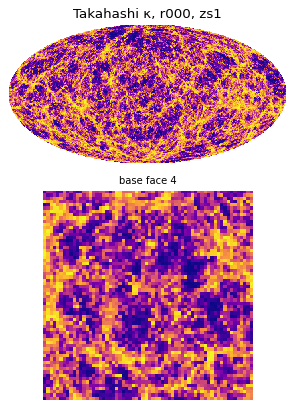

In [2]:
kappa = np.load(ROOT / "fixtures/takahashi/takahashi_r000_zs1_nside64_nested.npy").astype(np.float64)
nside = int(round((kappa.size / 12) ** 0.5))
z = (kappa - kappa.mean()) / kappa.std()
print(f"nside {nside}, {kappa.size} pixels, mean {kappa.mean():.3e}, std {kappa.std():.3e}, "
      f"skewness {np.mean(z**3):.2f}, excess kurtosis {np.mean(z**4) - 3:.1f}")
show_maps([kappa], ["Takahashi κ, r000, zs1"])

## 1. Gaussian anamorphosis

The pixel of rank `r` among `N` becomes `Φ⁻¹((r + 1/2) / N)`; the sorted values of κ are kept to
go back (this is `tools/gaussianize.py forward`).

In [3]:
from scipy.stats import norm
order = np.argsort(kappa, kind="stable")
g = np.empty_like(kappa)
g[order] = norm.ppf((np.arange(kappa.size) + 0.5) / kappa.size)
kappa_sorted = kappa[order]
np.save(WORK / "target_g.npy", g)
print(f"g: mean {g.mean():.1e}, std {g.std():.4f}")
# to 2 nside, each group of 4 children keeping its parent's value as mean (tools/resample_nested.py)
run(sys.executable, ROOT / "tools/resample_nested.py", "up", WORK / "target_g.npy", WORK / "target_g_up.npy", "--keep-mean")

g: mean 1.9e-17, std 1.0000


up 64 -> 128 (keep mean): std 9.9999e-01 -> 1.0142e+00; degrade(up(x)) - x: rms 8.356e-17 
[0.9 s]


## 2. Synthesis with `stl-synth`

`--weights ergodic` divides every squared residual by the spatial variance of that coefficient
on the target (a reduced χ²), so that every family is fitted; `L = 4` orientations and
`J = log2(128) − 1 = 6` scales are the defaults. One T4, from white noise.

{"evaluations":420,"loss_first":803.8351122024376,"loss_last":0.18279377346273357,"ranks":1,"seconds":56.97,"seconds_per_evaluation":0.136} 
[75.7 s]
420 evaluations, 0.136 s each
final residual per family, in ergodic sigma: {'S1': {'count': 24, 'max_sigma': 1.0531078970847596, 'rms_sigma': 0.4572241666075504}, 'S2': {'count': 24, 'max_sigma': 1.5375650163655226, 'rms_sigma': 0.43907805890892077}, 'S3': {'count': 336, 'max_sigma': 4.178638895652115, 'rms_sigma': 0.609304008434048}, 'S4': {'count': 3584, 'max_sigma': 2.725860211181721, 'rms_sigma': 0.4061321770473175}, 'mean': {'count': 1, 'max_sigma': 0.003427573520743249, 'rms_sigma': 0.003427573520743249}, 'var': {'count': 1, 'max_sigma': 0.3867998935178821, 'rms_sigma': 0.3867998935178821}}


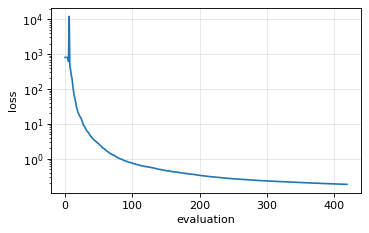

In [4]:
run(BIN / "stl-synth", "--target", WORK / "target_g_up.npy", "--weights", "ergodic", "--niter", 400,
    "--seed", 1, "--gpu", "--quiet", "--out", WORK / "synth_g")
rep = json.load(open(WORK / "synth_g.json"))
print(f"{rep['evaluations']} evaluations, {rep['seconds_per_evaluation']} s each")
print("final residual per family, in ergodic sigma:", rep["final_residual_in_ergodic_sigma"])
plt.figure(figsize=(5, 3)); plt.semilogy(rep["loss_history"]); plt.xlabel("evaluation"); plt.ylabel("loss")
plt.grid(alpha=0.3); plt.show()

## 3. Back to κ

The synthesis is in the target's units (here those of `g`), at nside 128: the mean of each group
of 4 children brings it back to nside 64. Then its pixel of rank `r` receives the `r`-th smallest
value of κ (`tools/gaussianize.py match`): the histogram is exactly the target's, and the spatial
structure is the synthesis'.

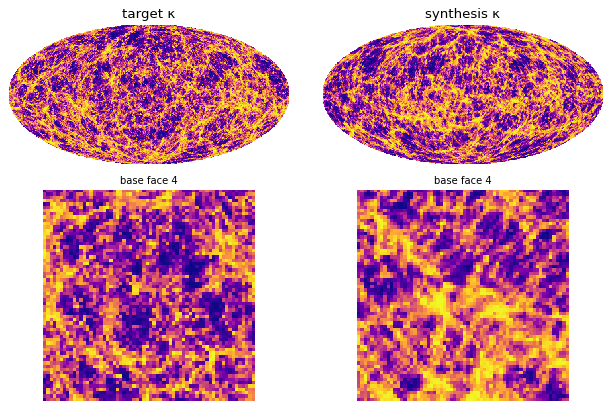

In [5]:
s_g = np.load(WORK / "synth_g_synthesis_nested.npy").reshape(-1, 4).mean(1)
np.save(WORK / "synth_g64.npy", s_g)
s_kappa = np.empty_like(s_g)
s_kappa[np.argsort(s_g, kind="stable")] = kappa_sorted
np.save(WORK / "synth_kappa.npy", s_kappa)
show_maps([kappa, s_kappa], ["target κ", "synthesis κ"])

## 4. Checks

Angular power spectra with the differentiable anafast of the package (`SpectrumEngine`, healpy's
conventions), and the scattering statistics of both maps with `stl-stats`, in the units of the
target (`--norm`).

SCRIPT VERSION: stl_port 2026-10-29-v2-variance-ratio


SCRIPT VERSION: stl_port.native 2026-11-06-v6


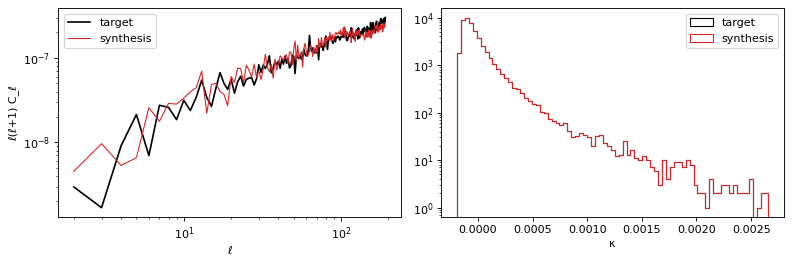

C_l ratio synthesis / target, mean over l = 2..3 nside-1: 1.0645141474469504


In [6]:
from stl_port.native import SpectrumEngine
spec = SpectrumEngine(nside, batch=2)
cl = spec.forward(np.stack([kappa, s_kappa]))
ell = np.arange(cl.shape[1])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].loglog(ell[2:], (ell * (ell + 1) * cl[0])[2:], "k", label="target")
ax[0].loglog(ell[2:], (ell * (ell + 1) * cl[1])[2:], "C3", lw=1, label="synthesis")
ax[0].set_xlabel("ℓ"); ax[0].set_ylabel("ℓ(ℓ+1) C_ℓ"); ax[0].legend()
bins = np.linspace(kappa.min(), np.percentile(kappa, 99.9), 80)
ax[1].hist(kappa, bins, histtype="step", color="k", label="target")
ax[1].hist(s_kappa, bins, histtype="step", color="C3", label="synthesis")
ax[1].set_yscale("log"); ax[1].set_xlabel("κ"); ax[1].legend()
plt.tight_layout(); plt.show()
print("C_l ratio synthesis / target, mean over l = 2..3 nside-1:", float(np.mean(cl[1, 2:] / cl[0, 2:])))

 
[16.7 s]


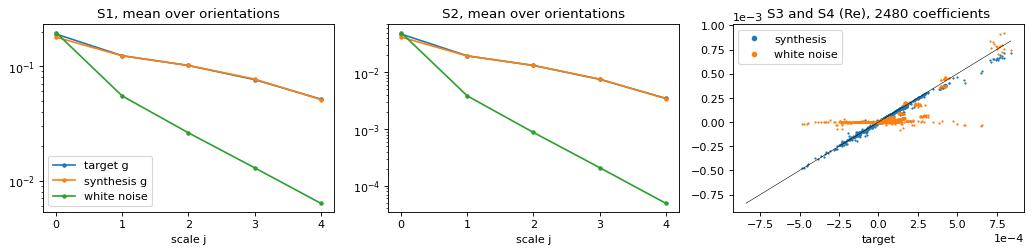

In [7]:
np.save(WORK / "white.npy", np.random.default_rng(0).standard_normal(kappa.size))
run(BIN / "stl-stats", "--out", WORK / "stats.json", "--norm", WORK / "target_g.npy", "--gpu", "--quiet", "--",
    WORK / "target_g.npy", WORK / "synth_g64.npy", WORK / "white.npy")
r = json.load(open(WORK / "stats.json"))
fam = np.array([c["family"] for c in r["plan"]]); j1 = np.array([c["j1"] for c in r["plan"]])
vals = [np.array(m["re"]) + 1j * np.array(m["im"]) for m in r["maps"]]
names = ["target g", "synthesis g", "white noise"]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for k, f in enumerate(["S1", "S2"]):
    for n, v in zip(names, vals):
        js = np.unique(j1[fam == f])
        ax[k].semilogy(js, [v[(fam == f) & (j1 == j)].real.mean() for j in js], "o-", ms=3, label=n)
    ax[k].set_title(f"{f}, mean over orientations"); ax[k].set_xlabel("scale j")
ax[0].legend()
sel = (fam == "S3") | (fam == "S4")
ax[2].plot(vals[0][sel].real, vals[1][sel].real, ".", ms=2, label="synthesis")
ax[2].plot(vals[0][sel].real, vals[2][sel].real, ".", ms=2, label="white noise")
lim = np.abs(vals[0][sel].real).max(); ax[2].plot([-lim, lim], [-lim, lim], "k", lw=0.5)
ax[2].set_title(f"S3 and S4 (Re), {sel.sum()} coefficients"); ax[2].set_xlabel("target"); ax[2].legend(markerscale=4)
ax[2].ticklabel_format(style="sci", scilimits=(0, 0))
plt.tight_layout(); plt.show()

## Going further

- **More resolution**: with a target at a higher nside, start the finer synthesis from this one
  (`--init synth_g64.npy --init-noise conditional`): the details drawn conditionally on the
  coarse map start the run close to the solution ({doc}`../user-guide/stl-synth`).
- **Ensembles** of maps whose mean statistics match this target (`--ensemble 10
  --scatter-weight 1`), or whose mean and variance match ten realisations (`stl-ensemble`,
  {doc}`../user-guide/stl-ensemble`).
- **Hold the physical map** directly: keep `g` as the variable and add the statistics of `κ = f(g)`
  with `--kappa-table`, the level power and the histogram tails (`--marginal-tail-weight`).